<center><h1>Liu_Yanchen_Midterm</h1></center>
<br>
<br>

Name: Yanchen Liu
<br>
Github Username: jamesnulliu

## 8. Programming Question: Predicting Final Grades with Linear Regression

**Dataset:** `student-mat.csv` from the UCI
[Student Performance](https://archive.ics.uci.edu/dataset/320/student+performance) data set
(Cortez & Silva, 2008). It describes 395 students in the mathematics course of two Portuguese
secondary schools with 33 attributes. The target is the final grade **G3**, on a 0–20 scale.

The models are built with `pandas` and `scikit-learn`; `statsmodels` is used only for the
p-values and variance inflation factors that back up the written answers.

Import packages

In [1]:
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import statsmodels.api as sm
from IPython.display import display
from scipy import stats
from sklearn.compose import ColumnTransformer
from sklearn.decomposition import PCA
from sklearn.linear_model import Lasso, LinearRegression, Ridge
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import KFold, cross_val_score, train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder, PolynomialFeatures, StandardScaler
from statsmodels.stats.outliers_influence import variance_inflation_factor

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.precision", 4)

SEED = 552

### (a) Data Exploration and Pre-processing

#### i. Import the `student-mat.csv` dataset as a pandas DataFrame

The path is relative to this notebook. The UCI file separates fields with `;`, not `,`.

In [2]:
DATA_PATH = "../data/student/student-mat.csv"

raw = pd.read_csv(DATA_PATH, sep=";")
print(f"shape: {raw.shape[0]} rows x {raw.shape[1]} columns")
raw.head()

shape: 395 rows x 33 columns


,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,...,4,3,4,1,1,3,6,5,6,6
1,GP,F,17,U,GT3,T,1,1,at_home,other,...,5,3,3,1,1,3,4,5,5,6
2,GP,F,15,U,LE3,T,1,1,at_home,other,...,4,3,2,2,3,3,10,7,8,10
3,GP,F,15,U,GT3,T,4,2,health,services,...,3,2,2,1,1,5,2,15,14,15
4,GP,F,16,U,GT3,T,3,3,other,other,...,4,3,2,1,2,5,4,6,10,10


In [3]:
raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 395 entries, 0 to 394
Data columns (total 33 columns):
 #   Column      Non-Null Count  Dtype
---  ------      --------------  -----
 0   school      395 non-null    str  
 1   sex         395 non-null    str  
 2   age         395 non-null    int64
 3   address     395 non-null    str  
 4   famsize     395 non-null    str  
 5   Pstatus     395 non-null    str  
 6   Medu        395 non-null    int64
 7   Fedu        395 non-null    int64
 8   Mjob        395 non-null    str  
 9   Fjob        395 non-null    str  
 10  reason      395 non-null    str  
 11  guardian    395 non-null    str  
 12  traveltime  395 non-null    int64
 13  studytime   395 non-null    int64
 14  failures    395 non-null    int64
 15  schoolsup   395 non-null    str  
 16  famsup      395 non-null    str  
 17  paid        395 non-null    str  
 18  activities  395 non-null    str  
 19  nursery     395 non-null    str  
 20  higher      395 non-null    str  
 21  inte

In [4]:
raw.describe().T

,count,mean,std,min,25%,50%,75%,max
age,395.0,16.6962,1.2760,15.0,16.0,17.0,18.0,22.0
Medu,395.0,2.7494,1.0947,0.0,2.0,3.0,4.0,4.0
Fedu,395.0,2.5215,1.0882,0.0,2.0,2.0,3.0,4.0
traveltime,395.0,1.4481,0.6975,1.0,1.0,1.0,2.0,4.0
studytime,395.0,2.0354,0.8392,1.0,1.0,2.0,2.0,4.0
failures,395.0,0.3342,0.7437,0.0,0.0,0.0,0.0,3.0
famrel,395.0,3.9443,0.8967,1.0,4.0,4.0,5.0,5.0
freetime,395.0,3.2354,0.9989,1.0,3.0,3.0,4.0,5.0
goout,395.0,3.1089,1.1133,1.0,2.0,3.0,4.0,5.0
Dalc,395.0,1.4810,0.8907,1.0,1.0,1.0,2.0,5.0


In [5]:
missing = raw.isna().sum()
print(f"missing values in the whole table: {missing.sum()}")
missing.to_frame("missing values").T

missing values in the whole table: 0


,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
missing values,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


#### ii. Select the features, encode `schoolsup`, combine `Dalc` and `Walc` into `alc`

`Dalc` (workday) and `Walc` (weekend) alcohol consumption are both on a 1–5 scale, so their
average `alc` stays on that scale in steps of 0.5.

In [6]:
FEATURES = ["age", "studytime", "schoolsup", "goout", "Dalc", "Walc", "health", "absences"]
TARGET = "G3"

df = raw[FEATURES + [TARGET]].copy()

# Binary variable: "no" -> 0, "yes" -> 1.
df["schoolsup"] = df["schoolsup"].map({"no": 0, "yes": 1}).astype(int)

# Average workday and weekend alcohol consumption, then drop the two originals.
df["alc"] = (df["Dalc"] + df["Walc"]) / 2
df = df.drop(columns=["Dalc", "Walc"])

# Keep the target as the last column.
df = df[[c for c in df.columns if c != TARGET] + [TARGET]]

X = df.drop(columns=TARGET)
y = df[TARGET]
X_COLS = list(X.columns)

print(f"pre-processed shape: {df.shape},  independent variables: {X_COLS}")
df.head()

pre-processed shape: (395, 8),  independent variables: ['age', 'studytime', 'schoolsup', 'goout', 'health', 'absences', 'alc']


,age,studytime,schoolsup,goout,health,absences,alc,G3
0,18,2,1,4,3,6,1.0,6
1,17,2,0,3,3,4,1.0,6
2,15,2,1,2,3,10,2.5,10
3,15,3,0,2,5,2,1.0,15
4,16,2,0,2,5,4,1.5,10


In [7]:
print(f"missing values after pre-processing: {df.isna().sum().sum()}")
print(f"students with G3 = 0: {(y == 0).sum()} of {len(y)}")
df.describe().T

missing values after pre-processing: 0
students with G3 = 0: 38 of 395


,count,mean,std,min,25%,50%,75%,max
age,395.0,16.6962,1.2760,15.0,16.0,17.0,18.0,22.0
studytime,395.0,2.0354,0.8392,1.0,1.0,2.0,2.0,4.0
schoolsup,395.0,0.1291,0.3358,0.0,0.0,0.0,0.0,1.0
goout,395.0,3.1089,1.1133,1.0,2.0,3.0,4.0,5.0
health,395.0,3.5544,1.3903,1.0,3.0,4.0,5.0,5.0
absences,395.0,5.7089,8.0031,0.0,0.0,4.0,8.0,75.0
alc,395.0,1.8861,0.9922,1.0,1.0,1.5,2.5,5.0
G3,395.0,10.4152,4.5814,0.0,8.0,11.0,14.0,20.0


#### iii. Number of outliers for each independent variable (IQR method)

A value is an outlier when it lies outside the fences
$[\,Q_1 - 1.5\,\mathrm{IQR},\; Q_3 + 1.5\,\mathrm{IQR}\,]$, where
$\mathrm{IQR} = Q_3 - Q_1$.

In [8]:
def iqr_outliers(s, k=1.5):
    """Quartiles, fences and outlier counts of one column under the k*IQR rule."""
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    lower, upper = q1 - k * iqr, q3 + k * iqr
    return {"Q1": q1, "Q3": q3, "IQR": iqr, "lower fence": lower, "upper fence": upper,
            "below": int((s < lower).sum()), "above": int((s > upper).sum()),
            "outliers": int(((s < lower) | (s > upper)).sum())}


outlier_table = pd.DataFrame({c: iqr_outliers(X[c]) for c in X_COLS}).T
outlier_table[["below", "above", "outliers"]] = outlier_table[["below", "above", "outliers"]].astype(int)
display(outlier_table)
print(f"total outlying values: {outlier_table['outliers'].sum()}\n")

# Which values are flagged in each column.
for c in X_COLS:
    lo, hi = outlier_table.loc[c, ["lower fence", "upper fence"]]
    flagged = X.loc[(X[c] < lo) | (X[c] > hi), c]
    if len(flagged):
        print(f"{c:>10}: {len(flagged):>3} outliers, values {sorted(flagged.unique().tolist())}")

,Q1,Q3,IQR,lower fence,upper fence,below,above,outliers
age,16.0,18.0,2.0,13.00,21.00,0,1,1
studytime,1.0,2.0,1.0,-0.50,3.50,0,27,27
schoolsup,0.0,0.0,0.0,0.00,0.00,0,51,51
goout,2.0,4.0,2.0,-1.00,7.00,0,0,0
health,3.0,5.0,2.0,0.00,8.00,0,0,0
absences,0.0,8.0,8.0,-12.00,20.00,0,15,15
alc,1.0,2.5,1.5,-1.25,4.75,0,9,9


total outlying values: 103

       age:   1 outliers, values [22]
 studytime:  27 outliers, values [4]
 schoolsup:  51 outliers, values [1]
  absences:  15 outliers, values [21, 22, 23, 24, 25, 26, 28, 30, 38, 40, 54, 56, 75]
       alc:   9 outliers, values [5.0]


Visualization for outlier detection

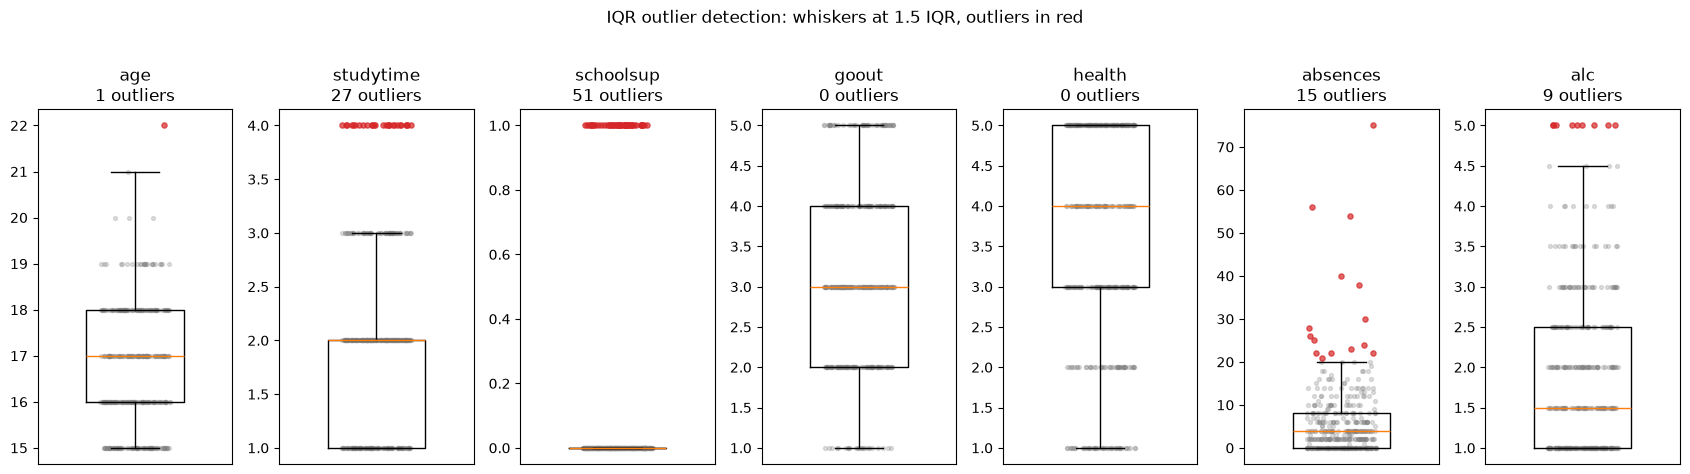

In [9]:
rng = np.random.default_rng(SEED)
fig, axes = plt.subplots(1, len(X_COLS), figsize=(17, 4.6))
for ax, c in zip(axes, X_COLS):
    lo, hi = outlier_table.loc[c, ["lower fence", "upper fence"]]
    is_out = (X[c] < lo) | (X[c] > hi)
    ax.boxplot(X[c], whis=1.5, widths=0.5, showfliers=False)
    # The variables are discrete, so jitter the points horizontally to show how many there are.
    jitter = 1 + rng.uniform(-0.18, 0.18, len(X))
    ax.scatter(jitter[~is_out], X.loc[~is_out, c], s=8, color="grey", alpha=0.25)
    ax.scatter(jitter[is_out], X.loc[is_out, c], s=14, color="tab:red", alpha=0.7)
    ax.set_title(f"{c}\n{int(is_out.sum())} outliers")
    ax.set_xticks([])
fig.suptitle("IQR outlier detection: whiskers at 1.5 IQR, outliers in red", y=1.02)
fig.tight_layout()
plt.show()

**Answer.** The IQR rule flags **103 values** in total:

| variable | outliers | what is flagged |
| --- | ---: | --- |
| `age` | 1 | the one 22-year-old (upper fence 21) |
| `studytime` | 27 | every student in the top category 4 (> 10 h/week); $Q_1 = 1$, $Q_3 = 2$ puts the upper fence at 3.5 |
| `schoolsup` | 51 | every "yes"; 87% of students are "no", so $Q_1 = Q_3 = 0$ and $\mathrm{IQR} = 0$ |
| `goout` | 0 | — |
| `health` | 0 | — |
| `absences` | 15 | students with more than 20 absences (up to 75) |
| `alc` | 9 | students who rate both workday and weekend drinking 5 (upper fence 4.75) |

Only `absences` has outliers in the usual sense: its distribution has a long right tail. For
the others the rule just picks out the end category of a short ordinal scale. For the binary
`schoolsup` the rule does not apply at all, because any minority value of a binary variable
falls outside a zero-width box.

All flagged values are valid survey answers, not entry errors, so every row is kept. The skew
of `absences` is dealt with in (b)ix.

#### iv. Standardize, run PCA, plot PC1 vs PC2 coloured by G3, inspect the loadings

PCA is run on the 7 independent variables. G3 is left out because it is the target and is
used to colour the points. Each feature is standardized to mean 0 and standard deviation 1.
The standardized matrix `X_std` is kept for all of part (b). G3 stays in grade points, so MAE
and RMSE in (b) are in grade points too.

In [10]:
scaler = StandardScaler()
X_std = pd.DataFrame(scaler.fit_transform(X), columns=X_COLS, index=X.index)
X_std.describe().loc[["mean", "std"]].round(3)

,age,studytime,schoolsup,goout,health,absences,alc
mean,0.000,-0.000,0.000,-0.000,0.000,-0.000,-0.000
std,1.001,1.001,1.001,1.001,1.001,1.001,1.001


In [11]:
pca = PCA()
scores = pca.fit_transform(X_std)
pc_names = [f"PC{i}" for i in range(1, len(X_COLS) + 1)]

explained = pd.DataFrame({"explained variance ratio": pca.explained_variance_ratio_,
                          "cumulative": pca.explained_variance_ratio_.cumsum()},
                         index=pc_names)
explained.T.round(3)

,PC1,PC2,PC3,PC4,PC5,PC6,PC7
explained variance ratio,0.237,0.171,0.152,0.14,0.127,0.095,0.078
cumulative,0.237,0.408,0.560,0.70,0.827,0.922,1.000


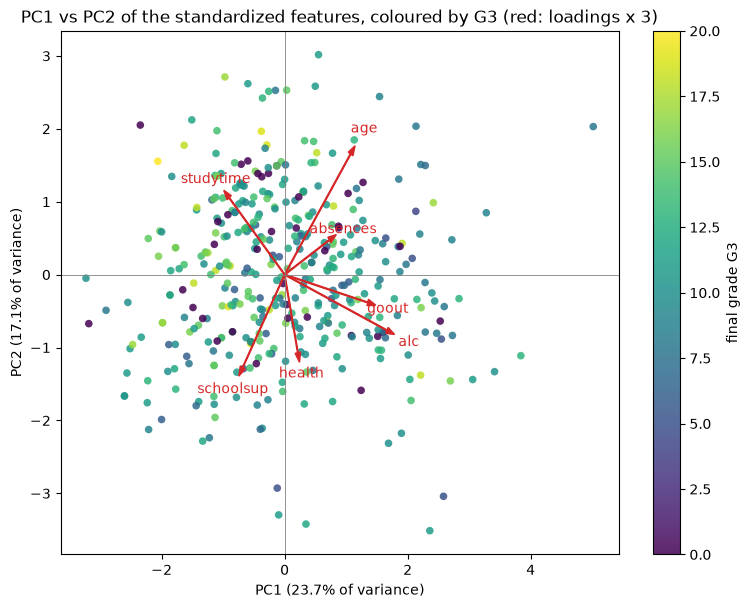

correlation with G3:  PC1 -0.131   PC2 +0.042


In [12]:
fig, ax = plt.subplots(figsize=(9, 6.8))
points = ax.scatter(scores[:, 0], scores[:, 1], c=y, cmap="viridis", s=30, alpha=0.85,
                    edgecolor="none")
fig.colorbar(points, ax=ax, label="final grade G3")

# Overlay the loading vectors (biplot), scaled up so they are visible next to the scores.
ARROW = 3.0
for name, (l1, l2) in zip(X_COLS, pca.components_[:2].T):
    ax.arrow(0, 0, ARROW * l1, ARROW * l2, color="tab:red", width=0.012, head_width=0.09,
             length_includes_head=True)
    ax.text(ARROW * l1 * 1.13, ARROW * l2 * 1.13, name, color="tab:red", fontsize=10,
            ha="center", va="center")
ax.axhline(0, color="grey", lw=0.6)
ax.axvline(0, color="grey", lw=0.6)
ax.set_xlabel(f"PC1 ({100 * pca.explained_variance_ratio_[0]:.1f}% of variance)")
ax.set_ylabel(f"PC2 ({100 * pca.explained_variance_ratio_[1]:.1f}% of variance)")
ax.set_title("PC1 vs PC2 of the standardized features, coloured by G3 (red: loadings x 3)")
plt.show()

print(f"correlation with G3:  PC1 {np.corrcoef(scores[:, 0], y)[0, 1]:+.3f}   "
      f"PC2 {np.corrcoef(scores[:, 1], y)[0, 1]:+.3f}")

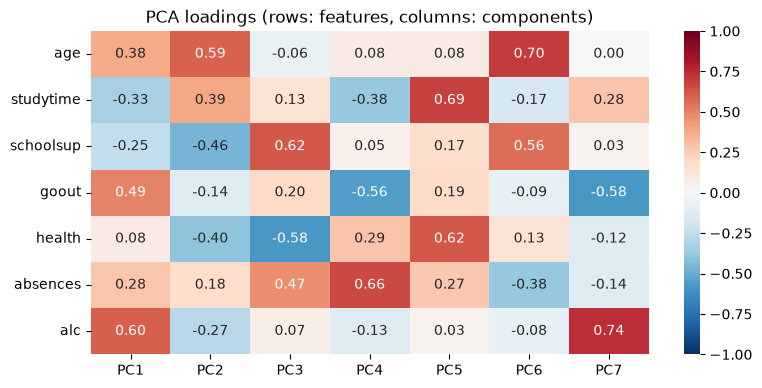

PC1: alc (+0.596), goout (+0.494), age (+0.382), studytime (-0.330), absences (+0.280), schoolsup (-0.248), health (+0.081)
PC2: age (+0.589), schoolsup (-0.464), health (-0.401), studytime (+0.386), alc (-0.274), absences (+0.183), goout (-0.140)


In [13]:
loadings = pd.DataFrame(pca.components_.T, index=X_COLS, columns=pc_names)

fig, ax = plt.subplots(figsize=(9, 4.2))
sns.heatmap(loadings, annot=True, fmt=".2f", cmap="RdBu_r", center=0, vmin=-1, vmax=1, ax=ax)
ax.set_title("PCA loadings (rows: features, columns: components)")
plt.show()

# Features ranked by the absolute size of their loading.
for pc in ["PC1", "PC2"]:
    order = loadings[pc].abs().sort_values(ascending=False).index
    print(f"{pc}: " + ", ".join(f"{f} ({loadings.loc[f, pc]:+.3f})" for f in order))

**Answer.**

* **The variance is spread out.** PC1 explains 23.7% of the variance and PC2 17.1%, together
  40.8%. If the 7 features were completely uncorrelated, each component would explain
  $1/7 = 14.3\%$. The features share little variance, so two components cannot summarise
  them.
* **PC1** is driven by **`alc` (+0.60), `goout` (+0.49), `age` (+0.38)** and, with the
  opposite sign, **`studytime` (−0.33)**. It is a "social life" axis: high PC1 means an older
  student who goes out and drinks more and studies less.
* **PC2** is driven by **`age` (+0.59), `schoolsup` (−0.46), `health` (−0.40)** and
  **`studytime` (+0.39)**. High PC2 means an older student who studies more and gets no extra
  school support.
* **G3 is not separated by either component.** High and low grades are mixed all over the
  scatter plot, with no colour gradient in any direction. The correlation with G3 is only
  −0.13 for PC1 and +0.04 for PC2. This already suggests that a linear model on these features
  will explain little of G3.

### (b) Linear Regression

#### i. Split the data into training and test sets (80:20, random seed 552)

The split uses the standardized features `X_std` from (a)iv.

In [14]:
X_train, X_test, y_train, y_test = train_test_split(X_std, y, test_size=0.2, random_state=SEED)

print(f"training set: {X_train.shape[0]} rows    test set: {X_test.shape[0]} rows")
print(f"mean G3:      training {y_train.mean():.2f}    test {y_test.mean():.2f}")
print(f"G3 = 0:       training {(y_train == 0).sum()}       test {(y_test == 0).sum()}")

training set: 316 rows    test set: 79 rows
mean G3:      training 10.61    test 9.62
G3 = 0:       training 27       test 11


#### ii. Build the three models on the training set ($\alpha = 0.1$)

scikit-learn minimises these objectives:

* **A. Linear Regression:** $\lVert y - X\beta \rVert_2^2$
* **B. Ridge:** $\lVert y - X\beta \rVert_2^2 + \alpha \lVert \beta \rVert_2^2$
* **C. Lasso:** $\dfrac{1}{2n}\lVert y - X\beta \rVert_2^2 + \alpha \lVert \beta \rVert_1$

The intercept is never penalised. Ridge's loss is a plain sum of squares, while Lasso's is
divided by $2n$. The same $\alpha = 0.1$ therefore regularises Lasso far more strongly than
Ridge (see (b)vii).

In [15]:
ALPHA = 0.1
models = {
    "A. Linear Regression": LinearRegression(),
    "B. Ridge (alpha=0.1)": Ridge(alpha=ALPHA),
    "C. Lasso (alpha=0.1)": Lasso(alpha=ALPHA),
}

for name, model in models.items():
    model.fit(X_train, y_train)
    print(f"{name:<22}  intercept {model.intercept_:.4f}   "
          f"training R2 {model.score(X_train, y_train):.4f}")

A. Linear Regression    intercept 10.6294   training R2 0.0748
B. Ridge (alpha=0.1)    intercept 10.6294   training R2 0.0748
C. Lasso (alpha=0.1)    intercept 10.6251   training R2 0.0714


#### iii. Test all three models: MAE, RMSE and $R^2$

In [16]:
def evaluate(y_true, y_pred):
    return {"MAE": mean_absolute_error(y_true, y_pred),
            "RMSE": np.sqrt(mean_squared_error(y_true, y_pred)),
            "R2": r2_score(y_true, y_pred)}


test_pred = {name: model.predict(X_test) for name, model in models.items()}
metrics = pd.DataFrame({name: evaluate(y_test, pred) for name, pred in test_pred.items()}).T

# Reference row (not a candidate): always predict the training mean of G3.
reference = pd.DataFrame(evaluate(y_test, np.full(len(y_test), y_train.mean())),
                         index=["(reference) predict training mean"])
display(pd.concat([metrics, reference]).round(4))

best = {"MAE": metrics["MAE"].idxmin(), "RMSE": metrics["RMSE"].idxmin(),
        "R2": metrics["R2"].idxmax()}
for metric, name in best.items():
    print(f"best {metric:<4}: {name}  ({metrics.loc[name, metric]:.4f})")

,MAE,RMSE,R2
A. Linear Regression,3.4180,4.7558,0.0282
B. Ridge (alpha=0.1),3.4181,4.7559,0.0282
C. Lasso (alpha=0.1),3.4471,4.7938,0.0126
(reference) predict training mean,3.5987,4.9255,-0.0424


best MAE : A. Linear Regression  (3.4180)
best RMSE: A. Linear Regression  (4.7558)
best R2  : A. Linear Regression  (0.0282)


**Answer.** **A. Linear Regression is best on all three metrics**: MAE 3.4180, RMSE 4.7558,
$R^2$ 0.0282. Ridge is practically identical to it; the two differ by less than 0.0001 on every
metric. Lasso is slightly worse on all three (MAE 3.4471, RMSE 4.7938, $R^2$ 0.0126).

Residual analysis

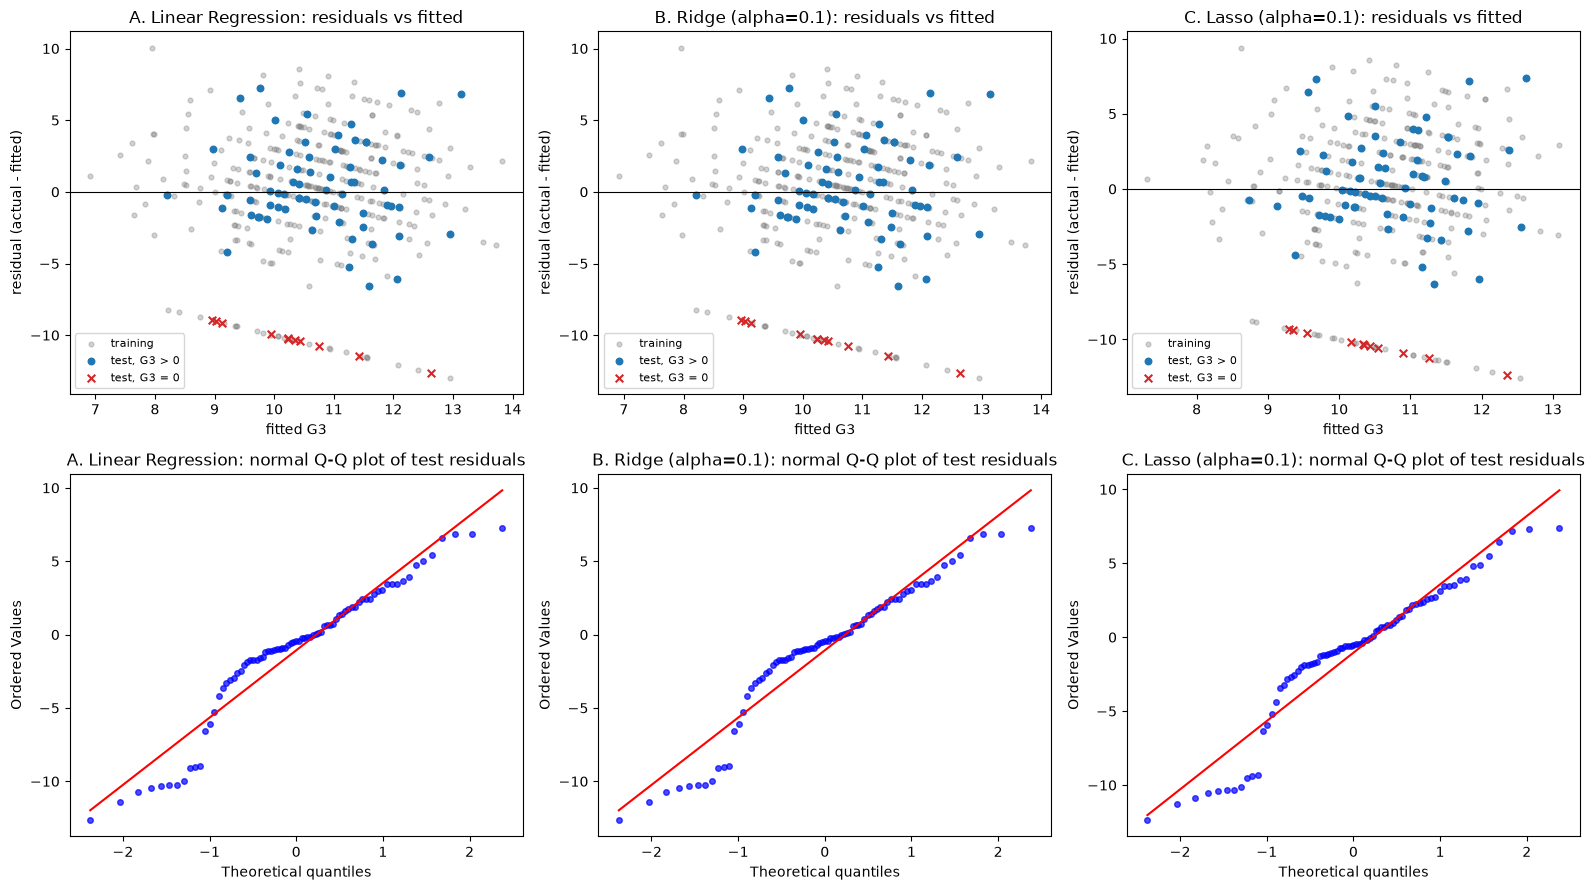

Linear Regression: fitted values on the test set range from 8.2 to 13.1; actual G3 ranges from 0 to 20
the 11 test students with G3 = 0 have residuals -12.6 to -9.0 and account for 65.8% of the test sum of squared errors


In [17]:
fig, axes = plt.subplots(2, 3, figsize=(16, 9))
for col, (name, model) in enumerate(models.items()):
    fit_train, fit_test = model.predict(X_train), test_pred[name]
    res_train, res_test = y_train - fit_train, y_test - fit_test
    zero = y_test == 0

    ax = axes[0, col]
    ax.scatter(fit_train, res_train, s=12, color="grey", alpha=0.35, label="training")
    ax.scatter(fit_test[~zero], res_test[~zero], s=22, color="tab:blue", label="test, G3 > 0")
    ax.scatter(fit_test[zero], res_test[zero], s=30, color="tab:red", marker="x",
               label="test, G3 = 0")
    ax.axhline(0, color="black", lw=0.8)
    ax.set_title(f"{name}: residuals vs fitted")
    ax.set_xlabel("fitted G3")
    ax.set_ylabel("residual (actual - fitted)")
    ax.legend(fontsize=8, loc="lower left")

    ax = axes[1, col]
    stats.probplot(res_test, dist="norm", plot=ax)
    ax.get_lines()[0].set(markersize=4, alpha=0.7)
    ax.set_title(f"{name}: normal Q-Q plot of test residuals")
fig.tight_layout()
plt.show()

res_ols = y_test - test_pred["A. Linear Regression"]
share = (res_ols[y_test == 0] ** 2).sum() / (res_ols ** 2).sum()
print(f"Linear Regression: fitted values on the test set range from "
      f"{test_pred['A. Linear Regression'].min():.1f} to "
      f"{test_pred['A. Linear Regression'].max():.1f}; actual G3 ranges from "
      f"{y_test.min()} to {y_test.max()}")
print(f"the {(y_test == 0).sum()} test students with G3 = 0 have residuals "
      f"{res_ols[y_test == 0].min():.1f} to {res_ols[y_test == 0].max():.1f} and account "
      f"for {100 * share:.1f}% of the test sum of squared errors")

**Residual analysis.** The three models produce almost the same picture:

* **The fitted values are squeezed into a narrow range.** On the test set they run from about
  8 to 13, while actual grades run from 0 to 20. The model predicts roughly "average" for
  everyone.
* **The G3 = 0 students form a separate diagonal band.** For them the residual is
  $0 - \hat{y} = -\hat{y}$, so they sit 9 to 13 points below the zero line. The 11 such test
  students are 14% of the test set but account for about two thirds of the squared error.
* **The residuals are not normal.** The Q-Q plots follow the line in the middle but have a
  long lower tail, which comes from the G3 = 0 band. Without those students the residuals
  look roughly symmetric with constant spread.

A grade of 0 marks students who did not sit the final exam, which is a different process from
earning a low grade. A linear model in these features cannot represent that point mass.

#### iv. How do you interpret the $R^2$ values from the three models?

**Answer.** $R^2 = 1 - \mathrm{SS}_\text{res}/\mathrm{SS}_\text{tot}$ is the fraction of the
variance of G3 in the test set that a model explains:

* Linear Regression and Ridge reach $R^2 = 0.028$ and Lasso $0.013$. The seven features
  explain **less than 3% of the variation** in final grades, and the remaining 97% comes from
  things they do not measure.
* On the training set the full model reaches only $R^2 = 0.075$. Its overall F-test is still
  significant ($p = 0.001$, see (b)vi), so the signal is real, but it is very weak.
* A model that always predicts the training mean scores $R^2 = -0.042$ on this test set. On
  test data $R^2$ can be negative, here because the test mean (9.62) differs from the training
  mean (10.61). Next to that baseline, Linear Regression lowers the RMSE only from 4.93 to
  4.76 grade points. That is still larger than the standard deviation of G3 itself (4.58),
  so the models cannot usefully predict an individual student's grade.
* The three $R^2$ values are nearly equal because the models are nearly identical. The
  difference between them is not a meaningful ranking.

#### v. Coefficients of the independent variables from the three models

In [18]:
coef_table = pd.DataFrame({name: np.r_[model.intercept_, model.coef_]
                           for name, model in models.items()},
                          index=["(intercept)"] + X_COLS)
display(coef_table.round(4))
print(f"Lasso coefficients set exactly to 0: "
      f"{[c for c, b in zip(X_COLS, models['C. Lasso (alpha=0.1)'].coef_) if b == 0]}")

,A. Linear Regression,B. Ridge (alpha=0.1),C. Lasso (alpha=0.1)
(intercept),10.6294,10.6294,10.6251
age,-0.7811,-0.7807,-0.6304
studytime,0.4448,0.4447,0.3491
schoolsup,-0.6825,-0.6822,-0.5475
goout,-0.5825,-0.5823,-0.4856
health,-0.2433,-0.2432,-0.1416
absences,0.1928,0.1927,0.0720
alc,0.0371,0.0369,-0.0000


Lasso coefficients set exactly to 0: ['alc']


#### vi. What's the relationship between each independent variable and the dependent variable?

Because the features are standardized, each coefficient is the change in predicted G3, in
grade points, for a one-standard-deviation increase in that feature, holding the others fixed.
The p-values come from refitting the same least-squares model on the training set with
`statsmodels`. The table also gives each feature's simple correlation with G3, over all
students and over the students with G3 > 0.

In [19]:
ols_sm = sm.OLS(y_train, sm.add_constant(X_train)).fit()

relation = pd.DataFrame({
    "coef (per 1 SD)": ols_sm.params[X_COLS],
    "p-value": ols_sm.pvalues[X_COLS],
    "corr with G3": X.corrwith(y),
    "corr with G3 (G3 > 0 only)": X[y > 0].corrwith(y[y > 0]),
})
display(relation.round(4))
print(f"training R2 {ols_sm.rsquared:.4f},  overall F-test p-value {ols_sm.f_pvalue:.4f}")
print(f"absences among the {(y == 0).sum()} students with G3 = 0: "
      f"{sorted(X.loc[y == 0, 'absences'].unique().tolist())}")

,coef (per 1 SD),p-value,corr with G3,corr with G3 (G3 > 0 only)
age,-0.7811,0.0030,-0.1616,-0.1404
studytime,0.4448,0.0794,0.0978,0.1267
schoolsup,-0.6825,0.0053,-0.0828,-0.2384
goout,-0.5825,0.0349,-0.1328,-0.1774
health,-0.2433,0.3221,-0.0613,-0.0817
absences,0.1928,0.4333,0.0342,-0.2131
alc,0.0371,0.8973,-0.0582,-0.1864


training R2 0.0748,  overall F-test p-value 0.0011
absences among the 38 students with G3 = 0: [0]


**Answer.** All relationships are weak. The largest effect is under 0.8 grade points per
standard deviation, on a 0–20 scale.

* **`age`: negative**, −0.78 (p = 0.003). Older students in the same course score lower. Many
  of them are repeating a year; age correlates +0.24 with past class failures.
* **`studytime`: positive**, +0.44 (p = 0.08). More weekly study goes with a higher grade, but
  the effect is only borderline significant.
* **`schoolsup`: negative**, −0.68 (p = 0.005). Students who receive extra educational support
  score lower. This is almost certainly reverse causation: support is given to students who
  are already struggling.
* **`goout`: negative**, −0.58 (p = 0.035). Going out with friends more often goes with lower
  grades.
* **`health`: negative but not significant**, −0.24 (p = 0.32).
* **`absences`: slightly positive and not significant**, +0.19 (p = 0.43). The positive sign is
  an artefact: all 38 students with G3 = 0 have exactly 0 absences, which pulls the slope up.
  Among students with G3 > 0 the correlation is **−0.21**, so more absences go with lower
  grades.
* **`alc`: no relationship**, +0.04 (p = 0.90). Once `goout` is in the model (the two correlate
  at +0.39), alcohol adds nothing, and Lasso drops it. Among students with G3 > 0, however, its
  correlation with G3 is −0.19.

So `age`, `schoolsup` and `goout` are the only predictors significant at the 5% level, and all
three lower the predicted grade.

#### vii. How do the regularization methods differ? What can you conclude about the dataset and features?

In [20]:
vif = pd.Series([variance_inflation_factor(sm.add_constant(X_train).values, i + 1)
                 for i in range(len(X_COLS))], index=X_COLS, name="VIF")

shrinkage = pd.DataFrame({
    "OLS": models["A. Linear Regression"].coef_,
    "Ridge - OLS": models["B. Ridge (alpha=0.1)"].coef_ - models["A. Linear Regression"].coef_,
    "|OLS| - |Lasso|": (np.abs(models["A. Linear Regression"].coef_)
                        - np.abs(models["C. Lasso (alpha=0.1)"].coef_)),
}, index=X_COLS)
display(pd.concat([shrinkage, vif], axis=1).round(4))

n = len(X_train)
print(f"Ridge shrinkage factor for an orthogonal design, n / (n + alpha) = {n / (n + ALPHA):.5f}")
print(f"training R2 {models['A. Linear Regression'].score(X_train, y_train):.4f}  vs  "
      f"test R2 {metrics.loc['A. Linear Regression', 'R2']:.4f}")

,OLS,Ridge - OLS,|OLS| - |Lasso|,VIF
age,-0.7811,0.0003,0.1507,1.1361
studytime,0.4448,-0.0002,0.0957,1.0755
schoolsup,-0.6825,0.0003,0.1350,1.0812
goout,-0.5825,0.0002,0.0969,1.1958
health,-0.2433,0.0001,0.1018,1.0146
absences,0.1928,-0.0001,0.1208,1.0503
alc,0.0371,-0.0002,0.0371,1.3036


Ridge shrinkage factor for an orthogonal design, n / (n + alpha) = 0.99968
training R2 0.0748  vs  test R2 0.0282


**Answer.**

**How the two penalties differ.**

* **Ridge (L2 penalty, $\alpha\sum\beta_j^2$)** shrinks every coefficient smoothly towards 0
  but never makes one exactly 0. It is most useful when features are correlated, because it
  stabilises their coefficients.
* **Lasso (L1 penalty, $\alpha\sum|\beta_j|$)** soft-thresholds the coefficients. When the
  features are nearly orthogonal, each coefficient moves roughly $\alpha$ towards 0, and any
  coefficient smaller than about $\alpha$ becomes exactly 0. Lasso therefore also selects
  features.

**What happened here.**

* **Ridge changed almost nothing.** Its penalty is not divided by $n$. With standardized
  features $X^\top X \approx nI$, so each coefficient is multiplied by about
  $n/(n+\alpha) = 316/316.1 = 0.9997$. Every Ridge coefficient differs from OLS by less than
  0.0005.
* **Lasso shrank every coefficient by roughly 0.1 to 0.15 grade points** and set **`alc`** to
  exactly 0, since its OLS coefficient (0.04) is below the threshold. The other six features
  survive.

**What this says about the dataset and the features.**

* **The features are nearly uncorrelated.** The VIFs are 1.01–1.30, consistent with the flat
  PCA spectrum in (a)iv. There is no multicollinearity for Ridge to fix.
* **The model is underfitting, not overfitting.** With 7 features and 316 training rows,
  training $R^2$ (0.075) and test $R^2$ (0.028) are both tiny. Regularization trades bias for
  variance, but this model has little variance to remove. That is why Ridge ties OLS and Lasso
  is slightly worse.
* **The problem is missing information, not model complexity.** The chosen features carry
  only a weak linear signal about G3, and the G3 = 0 point mass distorts it. Only `alc` is
  redundant, because `goout` already captures it.

#### viii. If the regularization strength ($\alpha$) is increased, what would happen to the performance metrics?

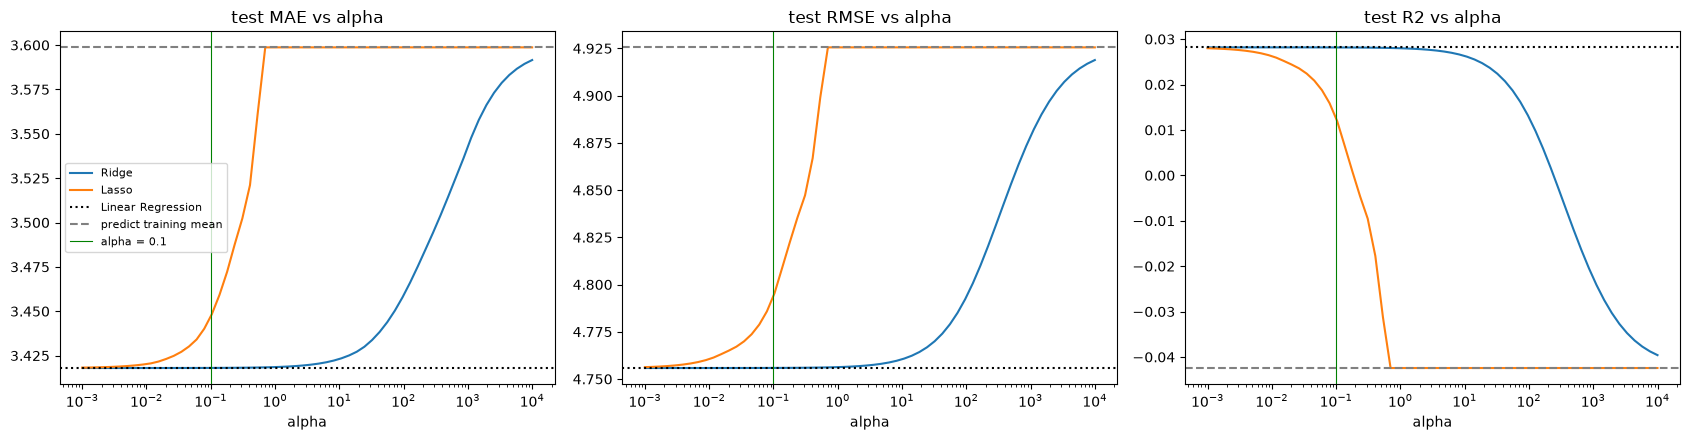

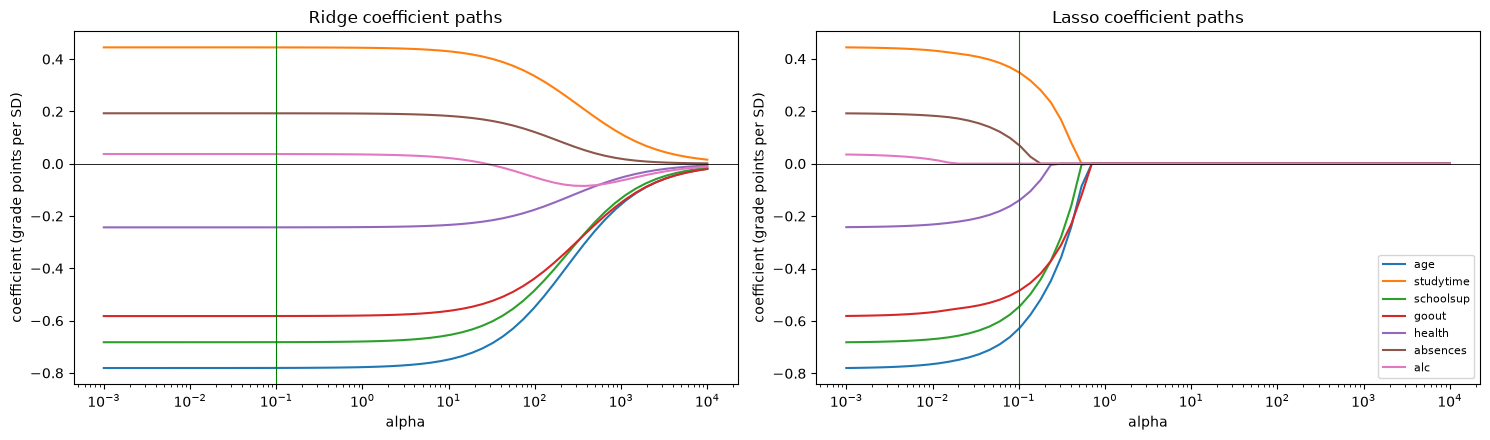

Lasso: every coefficient is 0 once alpha >= 0.663
Ridge: alphas that beat Linear Regression on test MAE or RMSE: 0
Lasso: alphas that beat Linear Regression on test MAE or RMSE: 0
Ridge alpha =     1:  MAE 3.4185  RMSE 4.7563  R2 0.0280
Ridge alpha =    10:  MAE 3.4231  RMSE 4.7604  R2 0.0263
Ridge alpha =   100:  MAE 3.4590  RMSE 4.7934  R2 0.0128
Ridge alpha =  1000:  MAE 3.5429  RMSE 4.8785  R2 -0.0226
Ridge alpha = 10000:  MAE 3.5916  RMSE 4.9188  R2 -0.0396


In [21]:
alphas = np.logspace(-3, 4, 60)
sweep = []
for alpha in alphas:
    for label, model in [("Ridge", Ridge(alpha=alpha)), ("Lasso", Lasso(alpha=alpha))]:
        model.fit(X_train, y_train)
        row = evaluate(y_test, model.predict(X_test))
        row.update(model=label, alpha=alpha, nonzero=int(np.sum(model.coef_ != 0)),
                   **dict(zip(X_COLS, model.coef_)))
        sweep.append(row)
sweep = pd.DataFrame(sweep)

ols_row = metrics.loc["A. Linear Regression"]
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
for ax, metric in zip(axes, ["MAE", "RMSE", "R2"]):
    for label, color in [("Ridge", "tab:blue"), ("Lasso", "tab:orange")]:
        part = sweep[sweep["model"] == label]
        ax.plot(part["alpha"], part[metric], color=color, label=label)
    ax.axhline(ols_row[metric], color="black", ls=":", label="Linear Regression")
    ax.axhline(reference[metric].iloc[0], color="grey", ls="--", label="predict training mean")
    ax.axvline(ALPHA, color="green", lw=0.8, label="alpha = 0.1")
    ax.set_xscale("log")
    ax.set_xlabel("alpha")
    ax.set_title(f"test {metric} vs alpha")
axes[0].legend(fontsize=8)
fig.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
for ax, label in zip(axes, ["Ridge", "Lasso"]):
    part = sweep[sweep["model"] == label]
    for c in X_COLS:
        ax.plot(part["alpha"], part[c], label=c)
    ax.axhline(0, color="black", lw=0.6)
    ax.axvline(ALPHA, color="green", lw=0.8)
    ax.set_xscale("log")
    ax.set_xlabel("alpha")
    ax.set_ylabel("coefficient (grade points per SD)")
    ax.set_title(f"{label} coefficient paths")
axes[1].legend(fontsize=8, loc="lower right")
fig.tight_layout()
plt.show()

# Smallest alpha at which Lasso sets every coefficient to 0.
alpha_max = np.max(np.abs(X_train.T @ (y_train - y_train.mean()))) / len(X_train)
print(f"Lasso: every coefficient is 0 once alpha >= {alpha_max:.3f}")
for label in ["Ridge", "Lasso"]:
    part = sweep[sweep["model"] == label]
    beats = part[(part["RMSE"] < ols_row["RMSE"] - 1e-9) | (part["MAE"] < ols_row["MAE"] - 1e-9)]
    print(f"{label}: alphas that beat Linear Regression on test MAE or RMSE: {len(beats)}")
for alpha in [1, 10, 100, 1000, 10000]:
    r = evaluate(y_test, Ridge(alpha=alpha).fit(X_train, y_train).predict(X_test))
    print(f"Ridge alpha = {alpha:>5}:  MAE {r['MAE']:.4f}  RMSE {r['RMSE']:.4f}  R2 {r['R2']:.4f}")

**Answer.** Increasing $\alpha$ shrinks the coefficients further towards 0. The predictions
therefore move towards the training mean, and the test metrics move from the Linear
Regression values (MAE 3.418, RMSE 4.756, $R^2$ 0.028) towards the intercept-only values
(MAE 3.599, RMSE 4.926, $R^2$ −0.042). On this dataset that means **MAE and RMSE rise and
$R^2$ falls**. No value of $\alpha$ in the sweep beats plain Linear Regression on the test
set.

* **Lasso degrades quickly.** Features drop out one at a time, `alc` first. Once
  $\alpha \ge \max_j |x_j^\top(y - \bar y)|/n = 0.663$, all seven coefficients are 0 and Lasso
  is exactly the intercept-only model.
* **Ridge degrades slowly.** Its penalty is not scaled by $n$, so nothing visible happens until
  $\alpha$ reaches the tens. It approaches the intercept-only model only asymptotically:
  $R^2$ is still −0.023 at $\alpha \approx 1000$, and Ridge never sets a coefficient exactly
  to 0.

In general, for a model with high variance (many correlated features, few rows), a moderate
increase in $\alpha$ can first *improve* test error before it eventually worsens. That is the
U-shaped bias–variance curve. Here the model is already underfitting (see (b)vii), so the
curve has no downhill part. More regularization only adds bias.

#### ix. What are some feature engineering methods you would suggest to improve model performance?

Each idea is checked with 5-fold cross-validated $R^2$ on the **training set only**, so the
test set is not used to choose between them. Every pipeline fits its scaler inside the CV
folds.

In [22]:
kf = KFold(n_splits=5, shuffle=True, random_state=SEED)
X_raw_train = X.loc[X_train.index]     # unscaled features of the training rows
extra = raw.loc[X_train.index]         # the other attributes of the same rows


def cv_r2(features, target=y_train, model=None):
    model = model if model is not None else make_pipeline(StandardScaler(), LinearRegression())
    scores = cross_val_score(model, features, target, cv=kf, scoring="r2")
    return {"CV R2 mean": scores.mean(), "CV R2 std": scores.std()}


log_abs = X_raw_train.assign(absences=np.log1p(X_raw_train["absences"]))
with_failures = X_raw_train.assign(failures=extra["failures"])
with_more = with_failures.assign(Medu=extra["Medu"], higher=(extra["higher"] == "yes").astype(int))
combined = log_abs.assign(failures=extra["failures"])

ORDINAL = ["studytime", "goout", "health"]
one_hot = ColumnTransformer([("onehot", OneHotEncoder(drop="first", handle_unknown="ignore"),
                              ORDINAL)], remainder=StandardScaler())
poly2 = make_pipeline(StandardScaler(), PolynomialFeatures(degree=2, include_bias=False),
                      LinearRegression())
positive = y_train > 0

experiments = pd.DataFrame({
    "baseline: the 7 features": cv_r2(X_raw_train),
    "log1p(absences)": cv_r2(log_abs),
    "+ failures": cv_r2(with_failures),
    "+ failures, Medu, higher": cv_r2(with_more),
    "log1p(absences) + failures": cv_r2(combined),
    "one-hot studytime, goout, health": cv_r2(X_raw_train, model=make_pipeline(one_hot, LinearRegression())),
    "degree-2 polynomial + interactions": cv_r2(X_raw_train, model=poly2),
    "G3 > 0 rows only (regression stage)": cv_r2(X_raw_train[positive], target=y_train[positive]),
}).T
experiments.round(4)

,CV R2 mean,CV R2 std
baseline: the 7 features,0.0178,0.0606
log1p(absences),0.0444,0.0981
+ failures,0.1109,0.0537
"+ failures, Medu, higher",0.0990,0.0758
log1p(absences) + failures,0.1345,0.0861
"one-hot studytime, goout, health",-0.0389,0.0956
degree-2 polynomial + interactions,-0.1197,0.1259
G3 > 0 rows only (regression stage),0.1327,0.0981


**Answer.** Suggested methods, in order of usefulness:

1. **Model the G3 = 0 students separately.** These 38 students did not sit the final exam,
   and they cause most of the squared error (see the residual analysis) and the wrong sign on
   `absences`. A two-stage model would work better: a classifier for "took the final exam?",
   then a regression for G3 among students who did. The regression stage alone, fitted on
   G3 > 0 rows, reaches CV $R^2 \approx 0.13$. Its `absences` effect becomes negative, as
   expected.
2. **Add more informative attributes.** The other 25 columns of the file contain much stronger
   predictors than the 7 chosen ones. `failures` (number of past class failures, correlation
   −0.36 with G3) lifts CV $R^2$ from 0.018 to 0.111 on its own. `Medu` and `higher` (wants
   higher education) also correlate with G3, but they add nothing in CV once `failures` is in
   the model. The period grades G1 and G2 would push $R^2$ far higher (correlations 0.80
   and 0.90 with G3). They should be used only if the goal is to predict G3 after those grades are
   known.
3. **Transform skewed features.** `log1p(absences)` tames the long tail that produced 15 IQR
   outliers and raises CV $R^2$ from 0.018 to 0.044. Together with `failures` it reaches
   0.134.
4. **Encode the ordinal 1–5 scales as categories, or add polynomial and interaction terms.**
   This lets the model capture non-linear effects; for example, a little going out may be
   harmless while a lot is not. With 316 rows, however, these extra columns overfit. One-hot
   encoding gives CV $R^2$ −0.039 and degree-2 terms −0.120, so they help only when paired with
   cross-validated regularization or more data.
5. **Combine correlated survey items into scores.** `alc` already does this for
   `Dalc`/`Walc`. Similar composites such as family support or a social-life index from
   `goout`/`freetime`/`romantic` reduce noise without adding many parameters.

Of the transforms checked above, adding `failures` and log-transforming `absences` give the
largest gains. Separating the G3 = 0 students addresses the dominant source of error.